# Complete E2E Kaggle: Hybrid PBS anemia screening (ResNet18 + 14-D + attention)

**Screening / research only — not for clinical diagnosis.**

**Adds vs minimal baseline:** cross-corpus option, largest-component morphology, aligned aug, hand-dim ablation, optional expert-mask IoU (CAS proxy), surrogate permutation importance, multi-seed training loop, Reinhard flag, McNemar, Grad-CAM, attention stats.

**CAS:** Full paper CAS may include extra terms; here we use **IoU(thresholded Grad-CAM, expert binary mask)** when `EXPERT_MASK_DIR` is set.

## What this notebook adds

| Item | |
|------|--|
| `NUM_WORKERS=0` (Kaggle) | yes |
| Auto `DATA_ROOT` | yes |
| Morphology: **largest** connected component | yes |
| Aligned flips for CNN + handcrafted | yes |
| `random_split` / `cross_corpus` / `POOL_I_AND_II` | yes |
| Hand dim shuffle ablation (14-D) | yes |
| Expert mask → IoU proxy for CAS | optional |
| RF surrogate + permutation importance (CNN vs hand mass) | yes |
| Multi-seed retrain | yes |
| Reinhard toggle | yes |
| CBC/EHR multimodal | not included (needs your CSV) |


In [1]:
# !pip install -q scipy

In [2]:
import random, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
    roc_auc_score,
)
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from torch.utils.data import DataLoader, Dataset
import torchvision.transforms.functional as TF
from torchvision.models import ResNet18_Weights, resnet18
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

# ================= CONFIG =================
SEEDS = [42]
IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 25
LR = 1e-4
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 0
USE_REINHARD = False

EVAL_PROTOCOL = "random_split"  # or "cross_corpus"
CORPUS_TRAIN = "AneRBC-II"
CORPUS_VAL = "AneRBC-I"
POOL_I_AND_II = False

CLASS_FOLDERS = ["Healthy_individuals", "Anemic_individuals"]
CLASS_NAMES = ["Healthy", "Anemic"]

EXPERT_MASK_DIR = None

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("DEVICE:", DEVICE)

DEVICE: cuda


In [3]:
# ================= DATA ROOT (FIXED) =================

DATA_ROOT = Path("/kaggle/input/datasets/nehalshivane/anemiadataset2prod/AnemiaDataset2Prod")

print("DATA_ROOT:", DATA_ROOT)

# sanity check
assert (DATA_ROOT / "AneRBC-I").exists(), "❌ AneRBC-I not found"
assert (DATA_ROOT / "AneRBC-II").exists(), "❌ AneRBC-II not found"

print("✅ Dataset structure verified!")

DATA_ROOT: /kaggle/input/datasets/nehalshivane/anemiadataset2prod/AnemiaDataset2Prod
✅ Dataset structure verified!


In [4]:
from skimage.color import lab2rgb, rgb2lab, rgb2gray
from skimage import measure
from skimage.feature import graycomatrix, graycoprops
from skimage.filters import threshold_otsu

def reinhard_lab_uint8(source_rgb, target_rgb):
    s = rgb2lab(source_rgb.astype(np.float64) / 255.0)
    t = rgb2lab(target_rgb.astype(np.float64) / 255.0)
    sm, tm = s.reshape(-1, 3).mean(0), t.reshape(-1, 3).mean(0)
    sstd = s.reshape(-1, 3).std(0) + 1e-6
    tstd = t.reshape(-1, 3).std(0) + 1e-6
    d = (s - sm) / sstd * tstd + tm
    rgb = lab2rgb(np.clip(d, 0, 100))
    return (np.clip(rgb, 0, 1) * 255.0).astype(np.uint8)

def get_mask_from_image(img_array):
    gray = rgb2gray(img_array)
    thresh = threshold_otsu(gray)
    return gray < thresh

def extract_morphology(mask):
    props = measure.regionprops(mask.astype(int))
    if not props:
        return np.zeros(6, dtype=np.float32)
    p = max(props, key=lambda r: r.area)
    area, perim = p.area, p.perimeter
    circ = 4 * np.pi * area / (perim ** 2 + 1e-8)
    return np.array([area, perim, circ, p.eccentricity, p.solidity, p.extent], dtype=np.float32)

def extract_glcm(gray_img):
    gray = (gray_img * 255).astype(np.uint8) if gray_img.max() <= 1 else gray_img.astype(np.uint8)
    glcm = graycomatrix(gray, [1], [0], levels=256, symmetric=True, normed=True)
    return np.array([
        graycoprops(glcm, "contrast")[0, 0],
        graycoprops(glcm, "correlation")[0, 0],
        graycoprops(glcm, "energy")[0, 0],
        graycoprops(glcm, "homogeneity")[0, 0],
    ], dtype=np.float32)

def extract_color(img_array):
    r, g, b = img_array[:, :, 0].mean(), img_array[:, :, 1].mean(), img_array[:, :, 2].mean()
    gray = rgb2gray(img_array)
    h, w = gray.shape
    center = gray[h // 4 : 3 * h // 4, w // 4 : 3 * w // 4]
    pallor = (center < center.mean()).sum() / (center.size + 1e-8)
    return np.array([r, g, b, pallor], dtype=np.float32)

def extract_14d_from_array(rgb_uint8):
    gray = rgb2gray(rgb_uint8).astype(np.float64)
    mask = get_mask_from_image(rgb_uint8)
    morph = extract_morphology(mask)
    texture = extract_glcm(gray)
    color = extract_color(rgb_uint8)
    return np.concatenate([morph, texture, color]).astype(np.float32)


In [5]:
def list_images(folder: Path):
    exts = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
    return sorted(str(p) for p in folder.rglob("*") if p.suffix.lower() in exts)

def find_class_image_dir(corpus_dir: Path, class_folder: str) -> Path:
    base = corpus_dir / class_folder
    for sub in ["Original_Images", "Original_images", "original_images"]:
        p = base / sub
        if p.is_dir():
            return p
    if base.is_dir():
        return base
    raise FileNotFoundError(base)

def collect_corpus_paths(root: Path, corpus_name: str):
    paths, labels = [], []
    cdir = root / corpus_name
    if not cdir.is_dir():
        raise FileNotFoundError(cdir)
    for li, cf in enumerate(CLASS_FOLDERS):
        idir = find_class_image_dir(cdir, cf)
        imgs = list_images(idir)
        paths.extend(imgs)
        labels.extend([li] * len(imgs))
    return paths, labels

root = Path(DATA_ROOT)
SPLIT_SEED = int(SEEDS[0])

if POOL_I_AND_II:
    paths, labels = [], []
    for corp in ["AneRBC-I", "AneRBC-II"]:
        p, y = collect_corpus_paths(root, corp)
        paths.extend(p)
        labels.extend(y)
        print(corp, len(p))
    train_idx, val_idx = train_test_split(
        np.arange(len(paths)), test_size=0.2, random_state=SPLIT_SEED, stratify=labels
    )
    train_paths = [paths[i] for i in train_idx]
    train_labels = [labels[i] for i in train_idx]
    val_paths = [paths[i] for i in val_idx]
    val_labels = [labels[i] for i in val_idx]
    print("Protocol: pooled random split")
elif EVAL_PROTOCOL == "cross_corpus":
    train_paths, train_labels = collect_corpus_paths(root, CORPUS_TRAIN)
    val_paths, val_labels = collect_corpus_paths(root, CORPUS_VAL)
    print("cross_corpus train", CORPUS_TRAIN, len(train_paths), "val", CORPUS_VAL, len(val_paths))
else:
    paths, labels = collect_corpus_paths(root, CORPUS_TRAIN)
    train_idx, val_idx = train_test_split(
        np.arange(len(paths)), test_size=0.2, random_state=SPLIT_SEED, stratify=labels
    )
    train_paths = [paths[i] for i in train_idx]
    train_labels = [labels[i] for i in train_idx]
    val_paths = [paths[i] for i in val_idx]
    val_labels = [labels[i] for i in val_idx]
    print("random_split on", CORPUS_TRAIN)

print("Train:", len(train_paths), "Val:", len(val_paths))
_ref = np.array(Image.open(train_paths[0]).convert("RGB").resize((IMG_SIZE, IMG_SIZE)))
REF_RGB = reinhard_lab_uint8(_ref, _ref) if USE_REINHARD else _ref


random_split on AneRBC-II
Train: 9600 Val: 2400


In [6]:
def raw_hand_for_paths(path_list, desc="scaler"):
    X = []
    for p in tqdm(path_list, desc=desc):
        im = Image.open(p).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
        rgb = np.array(im)
        if USE_REINHARD:
            rgb = reinhard_lab_uint8(rgb, REF_RGB)
        X.append(extract_14d_from_array(rgb))
    return np.stack(X, 0)

X_train_raw = raw_hand_for_paths(train_paths, "fit scaler")
scaler = StandardScaler()
scaler.fit(X_train_raw)


fit scaler:   0%|          | 0/9600 [00:00<?, ?it/s]

StandardScaler()

In [7]:
class AlignedHybridDataset(Dataset):
    def __init__(self, path_list, label_list, scaler, train, use_reinhard, ref_rgb):
        self.path_list = path_list
        self.label_list = label_list
        self.scaler = scaler
        self.train = train
        self.use_reinhard = use_reinhard
        self.ref_rgb = ref_rgb

    def __len__(self):
        return len(self.path_list)

    def __getitem__(self, idx):
        p = self.path_list[idx]
        y = self.label_list[idx]
        img = Image.open(p).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
        rgb = np.array(img)
        if self.use_reinhard:
            rgb = reinhard_lab_uint8(rgb, self.ref_rgb)
        if self.train:
            if random.random() < 0.5:
                rgb = np.fliplr(rgb).copy()
            if random.random() < 0.5:
                rgb = np.flipud(rgb).copy()
        hand = self.scaler.transform(extract_14d_from_array(rgb).reshape(1, -1)).astype(np.float32).ravel()
        t = TF.to_tensor(rgb)
        t = TF.normalize(t, IMAGENET_MEAN, IMAGENET_STD)
        return t, torch.from_numpy(hand), torch.tensor(y, dtype=torch.long)

class CNCDataset(Dataset):
    def __init__(self, path_list, label_list, train, use_reinhard, ref_rgb):
        self.path_list = path_list
        self.label_list = label_list
        self.train = train
        self.use_reinhard = use_reinhard
        self.ref_rgb = ref_rgb

    def __len__(self):
        return len(self.path_list)

    def __getitem__(self, idx):
        p = self.path_list[idx]
        y = self.label_list[idx]
        img = Image.open(p).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
        rgb = np.array(img)
        if self.use_reinhard:
            rgb = reinhard_lab_uint8(rgb, self.ref_rgb)
        if self.train:
            if random.random() < 0.5:
                rgb = np.fliplr(rgb).copy()
            if random.random() < 0.5:
                rgb = np.flipud(rgb).copy()
        t = TF.to_tensor(rgb)
        t = TF.normalize(t, IMAGENET_MEAN, IMAGENET_STD)
        return t, torch.tensor(y, dtype=torch.long)

def make_loaders(scaler_inst):
    train_h = AlignedHybridDataset(train_paths, train_labels, scaler_inst, True, USE_REINHARD, REF_RGB)
    val_h = AlignedHybridDataset(val_paths, val_labels, scaler_inst, False, USE_REINHARD, REF_RGB)
    train_c = CNCDataset(train_paths, train_labels, True, USE_REINHARD, REF_RGB)
    val_c = CNCDataset(val_paths, val_labels, False, USE_REINHARD, REF_RGB)
    kw = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=True)
    return (
        DataLoader(train_h, shuffle=True, **kw),
        DataLoader(val_h, shuffle=False, **kw),
        DataLoader(train_c, shuffle=True, **kw),
        DataLoader(val_c, shuffle=False, **kw),
    )

train_loader_h, val_loader_h, train_loader_c, val_loader_c = make_loaders(scaler)


In [8]:
class AttentionFusion(nn.Module):
    def __init__(self, cnn_dim=512, hand_dim=14, hidden_dim=256, num_classes=2, dropout=0.3):
        super().__init__()
        self.cnn_proj = nn.Linear(cnn_dim, hidden_dim)
        self.hand_proj = nn.Linear(hand_dim, hidden_dim)
        self.attention = nn.Sequential(
            nn.Linear(cnn_dim + hand_dim, 64), nn.ReLU(),
            nn.Linear(64, 2), nn.Softmax(dim=-1),
        )
        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden_dim, num_classes),
        )

    def forward(self, cnn_feat, hand_feat):
        combined = torch.cat([cnn_feat, hand_feat], dim=1)
        attn = self.attention(combined)
        cnn_proj = self.cnn_proj(cnn_feat)
        hand_proj = self.hand_proj(hand_feat)
        fused = attn[:, 0:1] * cnn_proj + attn[:, 1:2] * hand_proj
        return self.classifier(fused)

class HybridModel(nn.Module):
    def __init__(self, num_classes=2, pretrained=True, dropout=0.3):
        super().__init__()
        w = ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        backbone = resnet18(weights=w)
        self.features = nn.Sequential(*list(backbone.children())[:-1])
        self.fusion = AttentionFusion(512, 14, 256, num_classes, dropout)

    def forward(self, images, hand_feat):
        return self.fusion(self.features(images).flatten(1), hand_feat)

class CNNBaseline(nn.Module):
    def __init__(self, num_classes=2, pretrained=True, dropout=0.3):
        super().__init__()
        w = ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        backbone = resnet18(weights=w)
        self.features = nn.Sequential(*list(backbone.children())[:-1])
        self.head = nn.Sequential(
            nn.Linear(512, 256), nn.ReLU(), nn.Dropout(dropout), nn.Linear(256, num_classes)
        )

    def forward(self, x):
        return self.head(self.features(x).flatten(1))

class HybridConcat(nn.Module):
    def __init__(self, num_classes=2, pretrained=True, dropout=0.3):
        super().__init__()
        w = ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        backbone = resnet18(weights=w)
        self.features = nn.Sequential(*list(backbone.children())[:-1])
        self.head = nn.Sequential(
            nn.Linear(512 + 14, 256), nn.ReLU(), nn.Dropout(dropout), nn.Linear(256, num_classes)
        )

    def forward(self, images, hand_feat):
        x = torch.cat([self.features(images).flatten(1), hand_feat], dim=1)
        return self.head(x)


In [9]:
@torch.no_grad()
def evaluate_classifier(model, loader, device, hybrid=True):
    model.eval()
    ys, ps, pr = [], [], []
    for batch in loader:
        if hybrid:
            x, h, y = batch
            x, h, y = x.to(device), h.to(device), y.to(device)
            logits = model(x, h)
        else:
            x, y = batch
            x, y = x.to(device), y.to(device)
            logits = model(x)
        prob = F.softmax(logits, 1)[:, 1].cpu().numpy()
        pred = logits.argmax(1).cpu().numpy()
        ys.append(y.cpu().numpy())
        ps.append(pred)
        pr.append(prob)
    ys = np.concatenate(ys)
    ps = np.concatenate(ps)
    pr = np.concatenate(pr)
    acc = accuracy_score(ys, ps)
    p, r, f1, _ = precision_recall_fscore_support(ys, ps, average="macro", zero_division=0)
    try:
        auc = roc_auc_score(ys, pr)
    except Exception:
        auc = float("nan")
    return acc, p, r, f1, auc, ys, ps

def train_epochs(model, train_loader, val_loader, device, name, hybrid=True, path="best.pt"):
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
    crit = nn.CrossEntropyLoss(label_smoothing=0.05)
    best_acc, best_sd = 0.0, None
    model.to(device)
    for ep in range(1, EPOCHS + 1):
        model.train()
        tot = 0.0
        for batch in tqdm(train_loader, desc=f"{name} ep{ep}"):
            if hybrid:
                x, h, y = batch
                x, h, y = x.to(device), h.to(device), y.to(device)
                logits = model(x, h)
            else:
                x, y = batch
                x, y = x.to(device), y.to(device)
                logits = model(x)
            loss = crit(logits, y)
            opt.zero_grad()
            loss.backward()
            opt.step()
            tot += loss.item()
        sched.step()
        va, vp, vr, vf1, vauc, _, _ = evaluate_classifier(model, val_loader, device, hybrid=hybrid)
        print(f"{name} ep{ep} loss={tot/len(train_loader):.4f} val_acc={va:.4f} F1={vf1:.4f} auc={vauc}")
        if va > best_acc:
            best_acc = va
            best_sd = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            torch.save(best_sd, path)
    if best_sd is not None:
        model.load_state_dict(best_sd)
    return model, best_acc


In [10]:
results_rows = []
for run_idx, SEED in enumerate(SEEDS):
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    print("\n========== SEED", SEED, "==========")
    cnn = CNNBaseline(2, True)
    cnn, acc_cnn = train_epochs(
        cnn, train_loader_c, val_loader_c, DEVICE, f"cnn_{SEED}", False,
        f"/kaggle/working/best_cnn_{SEED}.pt",
    )
    hyb = HybridModel(2, True)
    hyb, acc_h = train_epochs(
        hyb, train_loader_h, val_loader_h, DEVICE, f"hyb_{SEED}", True,
        f"/kaggle/working/best_hybrid_{SEED}.pt",
    )
    cat = HybridConcat(2, True)
    cat, acc_cat = train_epochs(
        cat, train_loader_h, val_loader_h, DEVICE, f"cat_{SEED}", True,
        f"/kaggle/working/best_concat_{SEED}.pt",
    )
    results_rows.append({"seed": SEED, "cnn": acc_cnn, "hybrid": acc_h, "concat": acc_cat})

res_df = pd.DataFrame(results_rows)
print(res_df)
res_df.to_csv("/kaggle/working/val_acc_by_seed.csv", index=False)



========== SEED 42 ==========
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 171MB/s] 


cnn_42 ep1:   0%|          | 0/300 [00:00<?, ?it/s]

cnn_42 ep1 loss=0.3614 val_acc=0.9113 F1=0.9110 auc=0.9789798611111111


cnn_42 ep2:   0%|          | 0/300 [00:00<?, ?it/s]

cnn_42 ep2 loss=0.2849 val_acc=0.9171 F1=0.9168 auc=0.985932638888889


... (142 outputs left out)

cat_42 ep24:   0%|          | 0/300 [00:00<?, ?it/s]

cat_42 ep24 loss=0.1560 val_acc=0.9742 F1=0.9742 auc=0.9953736111111111


cat_42 ep25:   0%|          | 0/300 [00:00<?, ?it/s]

cat_42 ep25 loss=0.1552 val_acc=0.9746 F1=0.9746 auc=0.995498611111111
   seed      cnn  hybrid  concat
0    42  0.97375   0.975   0.975


In [11]:
import joblib

joblib.dump(scaler, "/kaggle/working/scaler.pkl")

for m, loader, hy, label in [
    (cnn, val_loader_c, False, "CNN"),
    (hyb, val_loader_h, True, "Hybrid-attn"),
    (cat, val_loader_h, True, "Hybrid-concat"),
]:
    acc, p, r, f1, auc, yt, yp = evaluate_classifier(m, loader, DEVICE, hybrid=hy)
    print(f"\n{label} acc={acc:.4f} P={p:.4f} R={r:.4f} F1={f1:.4f} AUC={auc}")
    print(confusion_matrix(yt, yp))
    print(classification_report(yt, yp, target_names=CLASS_NAMES))

try:
    from scipy.stats import binomtest

    _, _, _, _, _, yt, yp_c = evaluate_classifier(cnn, val_loader_c, DEVICE, False)
    _, _, _, _, _, _, yp_h = evaluate_classifier(hyb, val_loader_h, DEVICE, True)
    b = np.sum((yp_h != yt) & (yp_c == yt))
    c = np.sum((yp_c != yt) & (yp_h == yt))
    pval = binomtest(min(b, c), b + c, 0.5, alternative="two-sided").pvalue if (b + c) > 0 else float("nan")
    print(f"\nMcNemar b={b} c={c} p={pval}")
except Exception as e:
    print("McNemar:", e)



CNN acc=0.9738 P=0.9746 R=0.9738 F1=0.9737 AUC=0.9961506944444444
[[1143   57]
 [   6 1194]]
              precision    recall  f1-score   support

     Healthy       0.99      0.95      0.97      1200
      Anemic       0.95      0.99      0.97      1200

    accuracy                           0.97      2400
   macro avg       0.97      0.97      0.97      2400
weighted avg       0.97      0.97      0.97      2400


Hybrid-attn acc=0.9750 P=0.9755 R=0.9750 F1=0.9750 AUC=0.9963159722222221
[[1150   50]
 [  10 1190]]
              precision    recall  f1-score   support

     Healthy       0.99      0.96      0.97      1200
      Anemic       0.96      0.99      0.98      1200

    accuracy                           0.97      2400
   macro avg       0.98      0.98      0.97      2400
weighted avg       0.98      0.97      0.97      2400


Hybrid-concat acc=0.9750 P=0.9756 R=0.9750 F1=0.9750 AUC=0.9955131944444445
[[1149   51]
 [   9 1191]]
              precision    recall  f1-score   

In [12]:
@torch.no_grad()
def hybrid_acc_shuffled_dim(model, val_loader, device, dim_idx):
    model.eval()
    ys, ps = [], []
    for batch in val_loader:
        x, h, y = batch
        x, h, y = x.to(device), h.clone().to(device), y.to(device)
        perm = torch.randperm(h.size(0), device=device)
        h[:, dim_idx] = h[perm, dim_idx]
        logits = model(x, h)
        ys.append(y.cpu().numpy())
        ps.append(logits.argmax(1).cpu().numpy())
    return accuracy_score(np.concatenate(ys), np.concatenate(ps))

base_acc, _, _, _, _, _, _ = evaluate_classifier(hyb, val_loader_h, DEVICE, True)
print("Hybrid baseline val acc:", base_acc)
drops = []
for j in range(14):
    aj = hybrid_acc_shuffled_dim(hyb, val_loader_h, DEVICE, j)
    drops.append(base_acc - aj)
    print(f"  dim {j:2d} shuffled: acc={aj:.4f} delta={base_acc - aj:+.4f}")
np.save("/kaggle/working/hand_dim_ablation.npy", np.array(drops))


Hybrid baseline val acc: 0.975
  dim  0 shuffled: acc=0.9742 delta=+0.0008
  dim  1 shuffled: acc=0.9746 delta=+0.0004
  dim  2 shuffled: acc=0.9750 delta=+0.0000
  dim  3 shuffled: acc=0.9750 delta=+0.0000
  dim  4 shuffled: acc=0.9750 delta=+0.0000
  dim  5 shuffled: acc=0.9746 delta=+0.0004
  dim  6 shuffled: acc=0.9746 delta=+0.0004
  dim  7 shuffled: acc=0.9754 delta=-0.0004
  dim  8 shuffled: acc=0.9717 delta=+0.0033
  dim  9 shuffled: acc=0.9750 delta=+0.0000
  dim 10 shuffled: acc=0.9750 delta=+0.0000
  dim 11 shuffled: acc=0.9750 delta=+0.0000
  dim 12 shuffled: acc=0.9750 delta=+0.0000
  dim 13 shuffled: acc=0.9750 delta=+0.0000


In [13]:
@torch.no_grad()
def collect_embeddings(model, loader, device):
    model.eval()
    Es, Hs, Ys = [], [], []
    for x, h, y in loader:
        x = x.to(device)
        Es.append(model.features(x).flatten(1).cpu().numpy())
        Hs.append(h.numpy())
        Ys.append(y.numpy())
    return np.concatenate(Es), np.concatenate(Hs), np.concatenate(Ys)

E_tr, H_tr, Y_tr = collect_embeddings(hyb, train_loader_h, DEVICE)
E_va, H_va, Y_va = collect_embeddings(hyb, val_loader_h, DEVICE)
X_tr = np.hstack([E_tr, H_tr])
X_va = np.hstack([E_va, H_va])
rf = RandomForestClassifier(
    n_estimators=200, max_depth=12, random_state=SPLIT_SEED, n_jobs=-1
)
rf.fit(X_tr, Y_tr)
print("Surrogate RF val acc:", accuracy_score(Y_va, rf.predict(X_va)))
r = permutation_importance(rf, X_va, Y_va, n_repeats=8, random_state=SPLIT_SEED, n_jobs=-1)
print("PI sum CNN dims:", float(r.importances_mean[:512].sum()))
print("PI sum hand dims:", float(r.importances_mean[512:].sum()))
np.savez("/kaggle/working/surrogate_perm_importance.npz", mean=r.importances_mean, std=r.importances_std)


Surrogate RF val acc: 0.96625
PI sum CNN dims: -0.055624999999992625
PI sum hand dims: -0.0008333333333332416


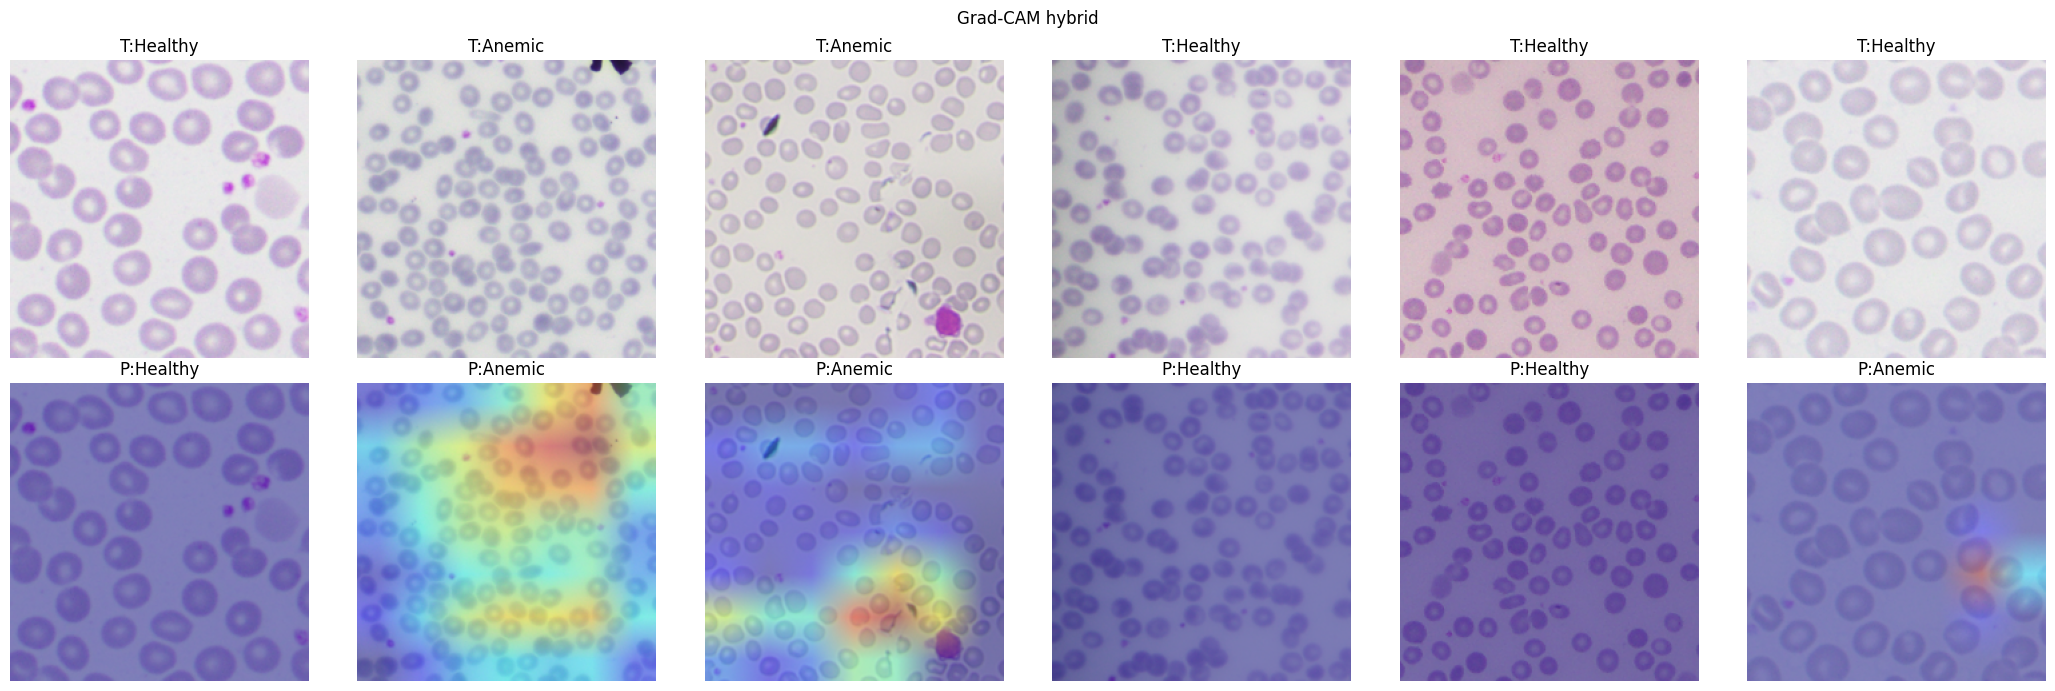

Mean IoU proxy: N/A (set EXPERT_MASK_DIR)


In [14]:
class GradCAM:
    def __init__(self, model, layer):
        self.model = model
        self.layer = layer
        self.act = self.grad = None

        def fh(m, i, o):
            self.act = o.detach()

        def bh(m, gi, go):
            self.grad = go[0].detach()

        self.h1 = layer.register_forward_hook(fh)
        self.h2 = layer.register_full_backward_hook(bh)

    def close(self):
        self.h1.remove()
        self.h2.remove()

    @torch.enable_grad()
    def __call__(self, img, hand, cls=None):
        self.model.eval()
        img = img.clone().detach().requires_grad_(True)
        logits = self.model(img, hand)
        if cls is None:
            cls = int(logits.argmax(1).item())
        self.model.zero_grad(set_to_none=True)
        logits[0, cls].backward()
        w = self.grad.mean((2, 3), keepdim=True)
        cam = (w * self.act).sum(1).clamp(min=0)[0].cpu().numpy()
        cam = (cam - cam.min()) / (np.ptp(cam) + 1e-8)
        return cam

hyb.eval()
gc = GradCAM(hyb, hyb.features[-2][-1].conv2)

import matplotlib.pyplot as plt

try:
    import cv2

    def overlay(rgb, cam, alpha=0.45):
        heat = cv2.applyColorMap((cam * 255).astype(np.uint8), cv2.COLORMAP_JET)
        heat = cv2.cvtColor(heat, cv2.COLOR_BGR2RGB)
        heat = cv2.resize(heat, (rgb.shape[1], rgb.shape[0]))
        return (alpha * heat + (1 - alpha) * rgb).astype(np.uint8)
except ImportError:
    def overlay(rgb, cam, alpha=0.45):
        return rgb

val_ds = val_loader_h.dataset
rng = np.random.default_rng(SPLIT_SEED)
ix = rng.choice(len(val_paths), size=min(6, len(val_paths)), replace=False)
fig, axes = plt.subplots(2, len(ix), figsize=(3.5 * len(ix), 7))
if len(ix) == 1:
    axes = np.array([[axes[0]], [axes[1]]])
cas_scores = []
for j, i in enumerate(ix):
    img_t, hand_t, y = val_ds[i]
    img_b = img_t.unsqueeze(0).to(DEVICE)
    hand_b = hand_t.unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        pred = hyb(img_b, hand_b).argmax(1).item()
    cam = gc(img_b, hand_b)
    rgb = np.array(Image.open(val_paths[i]).convert("RGB").resize((IMG_SIZE, IMG_SIZE)))
    if USE_REINHARD:
        rgb = reinhard_lab_uint8(rgb, REF_RGB)
    axes[0, j].imshow(rgb)
    axes[0, j].set_title(f"T:{CLASS_NAMES[val_labels[i]]}")
    axes[0, j].axis("off")
    axes[1, j].imshow(overlay(rgb, cam))
    axes[1, j].set_title(f"P:{CLASS_NAMES[pred]}")
    axes[1, j].axis("off")
    if EXPERT_MASK_DIR is not None:
        cand = Path(EXPERT_MASK_DIR) / Path(val_paths[i]).name
        if cand.is_file():
            em = np.array(Image.open(cand).convert("L").resize((IMG_SIZE, IMG_SIZE))) > 127
            gm = cam > np.quantile(cam, 0.8)
            cas_scores.append(
                np.logical_and(em, gm).sum() / (np.logical_or(em, gm).sum() + 1e-8)
            )
plt.suptitle("Grad-CAM hybrid")
plt.tight_layout()
plt.savefig("/kaggle/working/gradcam_val.png", dpi=150, bbox_inches="tight")
plt.show()
gc.close()
print("Mean IoU proxy:", float(np.mean(cas_scores)) if cas_scores else "N/A (set EXPERT_MASK_DIR)")


In [15]:
hyb.eval()
alphas = []
with torch.no_grad():
    for x, h, y in val_loader_h:
        x, h = x.to(DEVICE), h.to(DEVICE)
        cf = hyb.features(x).flatten(1)
        alphas.append(hyb.fusion.attention(torch.cat([cf, h], 1)).cpu().numpy())
A = np.concatenate(alphas, 0)
print("Attention mean [CNN, hand]:", A.mean(0), "std:", A.std(0))

torch.save(
    {
        "cnn": cnn.state_dict(),
        "hybrid": hyb.state_dict(),
        "concat": cat.state_dict(),
        "EVAL_PROTOCOL": EVAL_PROTOCOL,
        "CORPUS_TRAIN": CORPUS_TRAIN,
        "CORPUS_VAL": CORPUS_VAL,
        "USE_REINHARD": USE_REINHARD,
        "SEEDS": list(SEEDS),
    },
    "/kaggle/working/checkpoint_bundle.pt",
)
print("Saved /kaggle/working/checkpoint_bundle.pt")


Attention mean [CNN, hand]: [0.64218557 0.35781452] std: [0.33995572 0.33995572]
Saved /kaggle/working/checkpoint_bundle.pt


## Notes

- **Reinhard ablation:** set `USE_REINHARD = True` and re-run; compare `val_acc_by_seed.csv`.
- **Cross-corpus:** `EVAL_PROTOCOL = "cross_corpus"` and set `CORPUS_TRAIN` / `CORPUS_VAL`.
- **Multi-seed:** `SEEDS = [41, 42, 43]` — split stays tied to `SPLIT_SEED = SEEDS[0]` unless you change Cell 7.
- **Expert masks:** PNG binary masks, same filename as image, in `EXPERT_MASK_DIR`.
